# Revisión de muros especiales — ACI 318-25
Muro estructural especial con elementos de borde (§18.10). Cláusulas: §11, §18.10.2 (web), §18.10.3/4 (corte, Ve), §18.10.6 (elementos de borde), §22.2 (interacción).

**Unidades:** resultados en tonf / m; materiales en MPa.
**El diagrama out-of-plane (90°) y el Mpr fuera del plano ahora se muestrean correctamente.**

In [1]:
import sys, pathlib
# Make the notebook self-contained: add the repo root (the folder that
# contains design/common) to sys.path regardless of the run cwd.
ROOT = pathlib.Path.cwd()
for _ in range(5):
    if (ROOT / 'design' / 'common').is_dir():
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from design import Concrete, Steel, Bar, Beam, Column, Wall
from design import RectangularSection, WallSection
from design.beams.beam import BeamDemands
from design.columns.column import ColumnDemands
from design.walls.wall import WallDemands
from design.sections.reinforcement import RebarLayout, perimeter_bars, two_layer_bars
from design.common.units import units_from
from design.common.probable import mpr_at_axial, probable_interaction_diagram
from design.analysis.section_analysis import pm_curve

# Presentation: results in tonf / m ; materials in MPa (N/mm^2)
U = units_from('Tonf_m_C')      # forces -> tonf, moments -> tonf*m, lengths -> m
MAT = units_from('N_mm_C')      # stresses -> MPa
print('Results in:', U.name, '| materials in:', MAT.name)
print('1 tonf =', round(1/U.force_factor, 5), 'kN')


Results in: Tonf_m_C | materials in: N_mm_C
1 tonf = 9.80665 kN


In [2]:
def plot_pm(diagram, *, title, demand=None, mark_p0=True, nominal=None):
    """Plot a phi-reduced P-M interaction diagram (tonf, tonf*m), marking
    the Mpr at zero axial and an optional demand point."""
    Mn = np.array(diagram.phi_Mn) * U.moment_factor
    Pn = np.array(diagram.phi_Pn) * U.force_factor
    fig, ax = plt.subplots(figsize=(5.2, 5.6))
    ax.plot(Mn, Pn, '-', lw=2, color='#1f77b4', label='phi P-M (design)')
    if nominal is not None:
        Mnn = np.array([p.Mn for p in nominal.points]) * U.moment_factor
        Pnn = np.array([p.Pn for p in nominal.points]) * U.force_factor
        order = np.argsort(Pnn)
        ax.plot(Mnn[order], Pnn[order], '--', lw=1.2, color='#888',
                label='nominal P-M')
    if mark_p0:
        # moment at P = 0 (Mpr-style) read off the nominal curve
        if nominal is not None:
            order = np.argsort([p.Pn for p in nominal.points])
            Pn_s = np.array([nominal.points[i].Pn for i in order])
            Mn_s = np.array([nominal.points[i].Mn for i in order])
            m0 = float(np.interp(0.0, Pn_s, Mn_s)) * U.moment_factor
            ax.plot(m0, 0.0, 'o', color='crimson', ms=8,
                    label=f'M at P=0 = {m0:.1f} tonf*m')
    if demand is not None:
        md_, pd_ = demand
        ax.plot(md_, pd_, 's', color='green', ms=9, label='demand')
    ax.axhline(0, color='k', lw=0.6)
    ax.set_xlabel('phi*Mn  [tonf*m]'); ax.set_ylabel('phi*Pn  [tonf]')
    ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


## Ejercicio 1 — Evaluar un muro con armado mínimo
Muro 300×4000 con $\rho$ distribuido mínimo 0.0025 (§18.10.2.1) y elementos de borde de partida (línea base).

In [3]:
c = Concrete(fc=28); s = Steel(fy=420, grade=60)
wall = Wall.rectangular(lw=4000, tw=300, hw=24000, lu=3000,
    concrete=c, steel=s, n_y_web=12, db_web=12,
    be_top_length=600, be_bot_length=600, n_y_be=5, db_be=25,
    cover=40, seismic=True, units='Tonf_m_C')
wall.run(); wall.summary()

=== Wall ===  (units: Tonf_m_C)
Section : lw = 4.000 m, tw = 0.300 m
Heights : hw = 24.000 m, lu = 3.000 m
Material: fc = 28 MPa, fyt = 420 MPa
Web rho : rho_l = 0.0025, rho_t = 0.0025
BE top  : 0.300 m x 0.600 m
BE bot  : 0.300 m x 0.600 m
Po      : 3497.9 Tonf
To      : -620.8 Tonf
phi*Vn  : 178.9 Tonf  (cap = 537.4 Tonf)
max phi*Mn (in-plane)    : 1887.6 Tonf.m
max phi*Mn (out-of-plane): 105.4 Tonf.m
Steel quantities (kg/m^3 of concrete):
  rho_long  = 17.76
  rho_trans = 29.59
  rho_total = 47.35


### 1.2 Capacidad: BE evaluados, diagramas y Mpr in/out-of-plane
`capacity()` ahora evalúa los elementos de borde (cada BE es una columna real) y reporta el $M_{pr}$ in-plane, out-of-plane y a $P=0$.

In [4]:
cap = wall.capacity(biaxial=True)
print('has BE          :', cap.has_boundary_elements)
print('Po              =', U.fmt_force(cap.Po), '| To =', U.fmt_force(cap.To))
print('phi_Vn          =', U.fmt_force(cap.phi_Vn), '(max', U.fmt_force(cap.Vn_max), ')')
print('max phi_Mn in   =', U.fmt_moment(max(cap.diagram.phi_Mn)))
print('max phi_Mn out  =', U.fmt_moment(max(cap.diagram_out.phi_Mn)))
print('Mpr in-plane    =', U.fmt_moment(cap.Mpr_in_plane), '@Pu', U.fmt_force(cap.Pu_at_Mpr_in_plane))
print('Mpr in @ P=0    =', U.fmt_moment(cap.Mpr_in_plane_at_zero))
print('Mpr out-of-plane=', U.fmt_moment(cap.Mpr_out_of_plane))

has BE          : True
Po              = 3497.9 Tonf | To = -620.8 Tonf
phi_Vn          = 178.9 Tonf (max 537.4 Tonf )
max phi_Mn in   = 1887.6 Tonf.m
max phi_Mn out  = 105.4 Tonf.m
Mpr in-plane    = 2498.2 Tonf.m @Pu 1201.6 Tonf
Mpr in @ P=0    = 1366.5 Tonf.m
Mpr out-of-plane= 86.3 Tonf.m


### 1.3 Diagramas de interacción in-plane y out-of-plane
El diagrama fuera del plano (90°) — corregido — coincide con la sección equivalente y ya no sale colapsado.

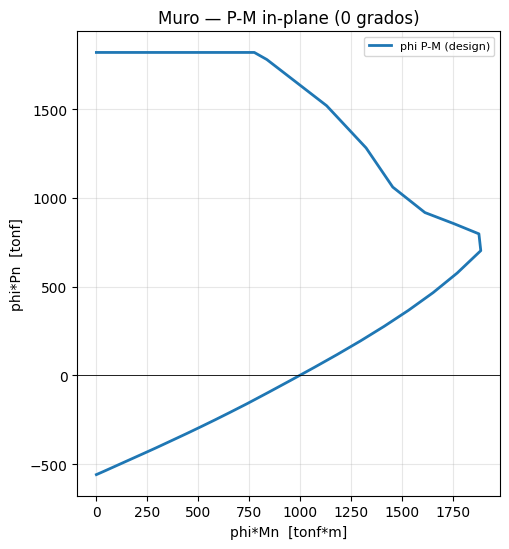

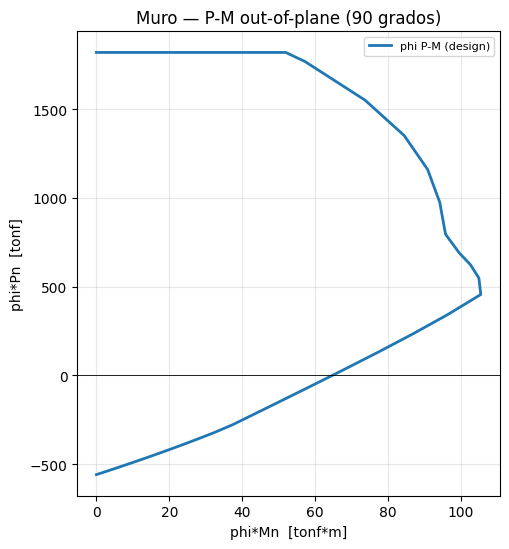

In [5]:
plot_pm(cap.diagram, title='Muro — P-M in-plane (0 grados)')
plot_pm(cap.diagram_out, title='Muro — P-M out-of-plane (90 grados)')

### 1.4 Verificación integral frente a demandas
`check()` verifica el muro **y** sus elementos de borde: confinamiento (Ash §18.10.6.4(g)), $\rho$ longitudinal del BE, capacidad de deriva (§18.10.6.2b) y ancho (§18.10.6.2(b)(ii)).

In [6]:
dem = WallDemands(Pu=3000, Mu=8000, Vu=1500, delta_u=0.008*24000)
chk = wall.check(dem)
chk.summary(units=wall.units)

=== Wall check ===


  PM (in-plane)  : ratio = 0.562    [PASS]
  Shear in-plane : ratio = 0.855    [PASS]
  Distrib. rho   : web rho_l/rho_t vs min   [PASS]
  Double curtain : feasibility               [PASS]
  BE by displ.   : required = True    (Sec.18.10.6.2)
  BE by stress   : required = False   (Sec.18.10.6.3)
    BE length req. : 0.373 m
    BE thickness   : >= 0.188 m
    BE present     : True            [PASS]
    BE confinement : Ash/hx/s (Sec.18.10.6.4)   [FAIL]
    BE long. rho   : 0.0327 vs min 0.0100   [PASS]
    Drift capacity : 0.0280 vs 1.5*demand 0.0120  (Sec.18.10.6.2b)  [PASS]
    BE width       : PASS  (b >= 273 mm, Sec.18.10.6.2(b)(ii))
  Tension-control: eps_t = 0.0128    phi @ Pu = 0.900    [PASS]
  ---
  passed         : False
  ---
  Steel quantities (kg/m^3 of concrete):
    rho_long  =   17.76
    rho_trans =   29.59
    rho_total =   47.35


## Ejercicio 2 — Diseño integral desde la sección y las demandas
`design()` propone el web, los elementos de borde (geometría + longitudinal desde la línea base + confinamiento Ash) y el Ve.

In [7]:
res = wall.design(dem)
wall.print_final(res.envelope, dem)


  WALL -- FINAL DESIGN   |   Wall   |   units: Tonf_m_C
  Section          : lw = 4.000 m   tw = 0.300 m   hw = 24.000 m
  Materials        : fc' = 28 MPa    fyt = 420 MPa
----------------------------------------------------------------------------
  Web distributed reinforcement:
    rho_l (vert)   = 0.0025   (req 0.0025)
    rho_t (horiz)  = 0.0025   (req 0.0025)
    bars           : phi12 @ 0.302 m    layers = 2
    double curtain : True
  Boundary elements:
    required       : True (by disp=True, by stress=False)
    length         = 0.373 m
    thickness      = 0.300 m
    extension above= 4.000 m   below = 4.000 m
    BE confinement (top, Sec.18.10.6.4(g)):
      Ash req x/y  = 218 / 481 mm^2   prov 402/603
      hoops        = phi16 @ 0.075 m   legs 2x3
----------------------------------------------------------------------------
  Capacities:
    Po              = 3497.9 Tonf
    To              = -620.8 Tonf
    phi*Vn          = 178.9 Tonf    (max = 537.4 Tonf)
    max phi*M

## Resumen
- **Diseño integral del muro:** `capacity()` evalúa los BE, `check()` verifica su armado (confinamiento + $\rho$ long.), `design()` los dimensiona desde una **línea base**.
- **Disparador de BE §18.10.6.2a** con el factor 1.5; **capacidad de deriva §18.10.6.2b** y **ancho §18.10.6.2(b)(ii)**.
- **Diagrama out-of-plane y $M_{pr}$ fuera del plano** correctos (corrección del muestreo de la profundidad rotada).